<a href="https://colab.research.google.com/github/marcus62-wq/Adaptive-Matrix-Geometric-Series/blob/main/TLM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TLM — TIME AND FREQUENCY DOMAINS
Status: reconstruction with declared assumptions.
No output-voltage calibration.
Boundary assumption: open
Node spacing: 2.000 m
Network size: 11 × 11
Time step: 4.717309 ns
Background line impedance: 532.777119 Ω
Input-current time constants: 0.983479 µs and 10.075095 µs

Running without ionization...

IONIZATION NOT RUN:
ECR_DOCUMENTADO is None.
Reference curves with ionization will still be shown,
but no calculated nonlinear curve will be invented.

PEAK VOLTAGE COMPARISON


,Point,Condition,Reference peak (kV),Calculated peak (kV),Relative error (%),Calculated peak time (µs)
0,A,Without ionization,164.9,73.3036,-55.5466,0.0283
1,B,Without ionization,40.0,39.8416,-0.3960,1.5426
2,C,Without ionization,37.4,37.8518,1.2081,2.5709



Time/frequency consistency — relative L2 difference: 0.005349%
End-of-record voltage / maximum voltage: 4.959719e-06
This comparison checks the same numerical network.
It does not establish validation against the article.


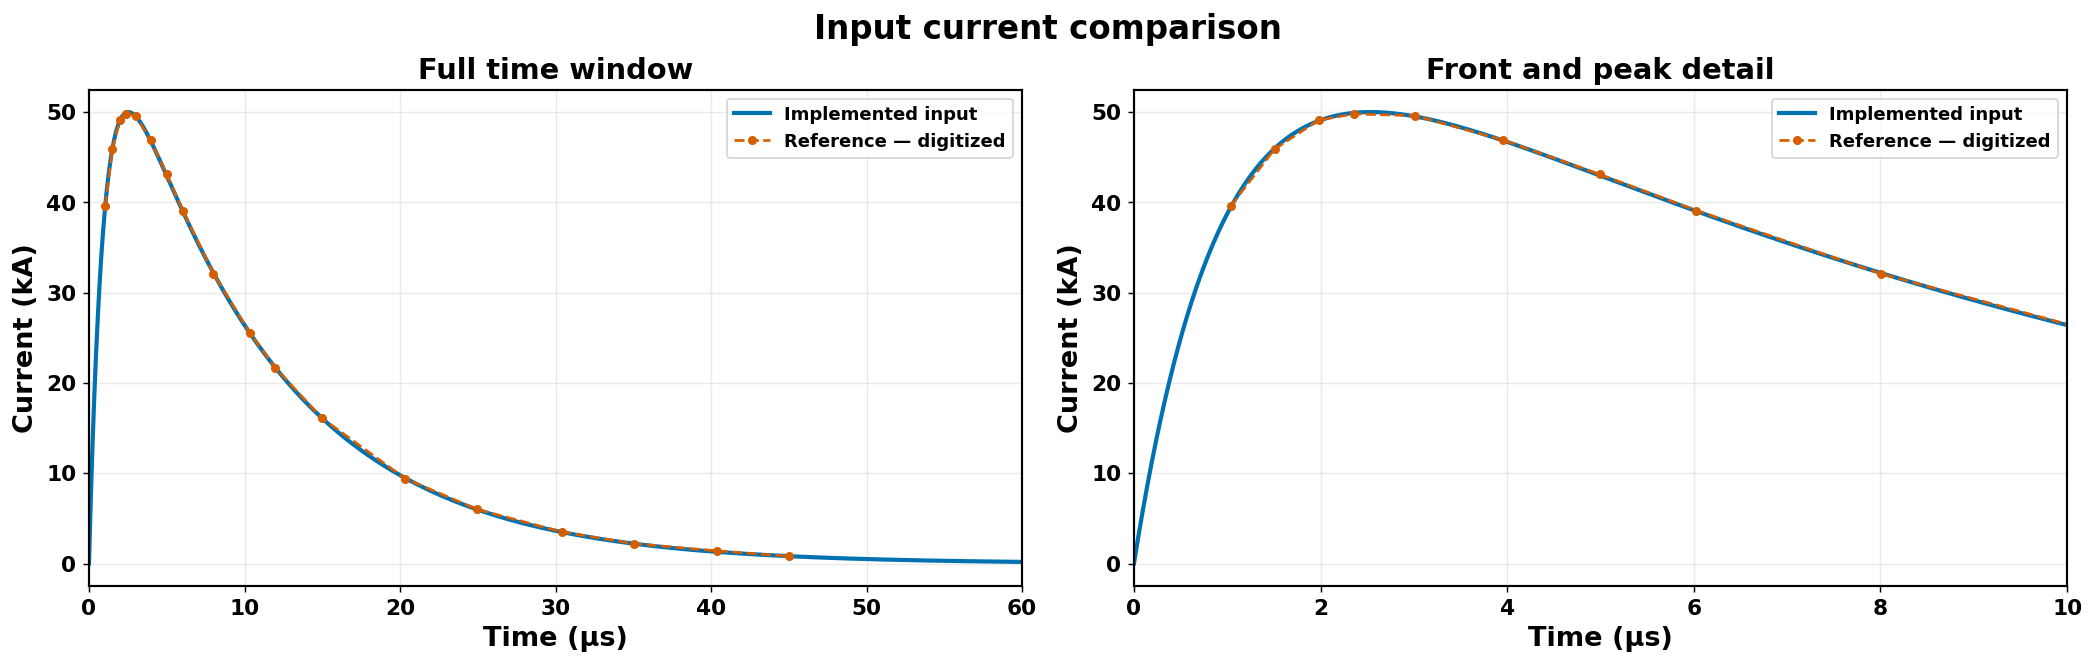

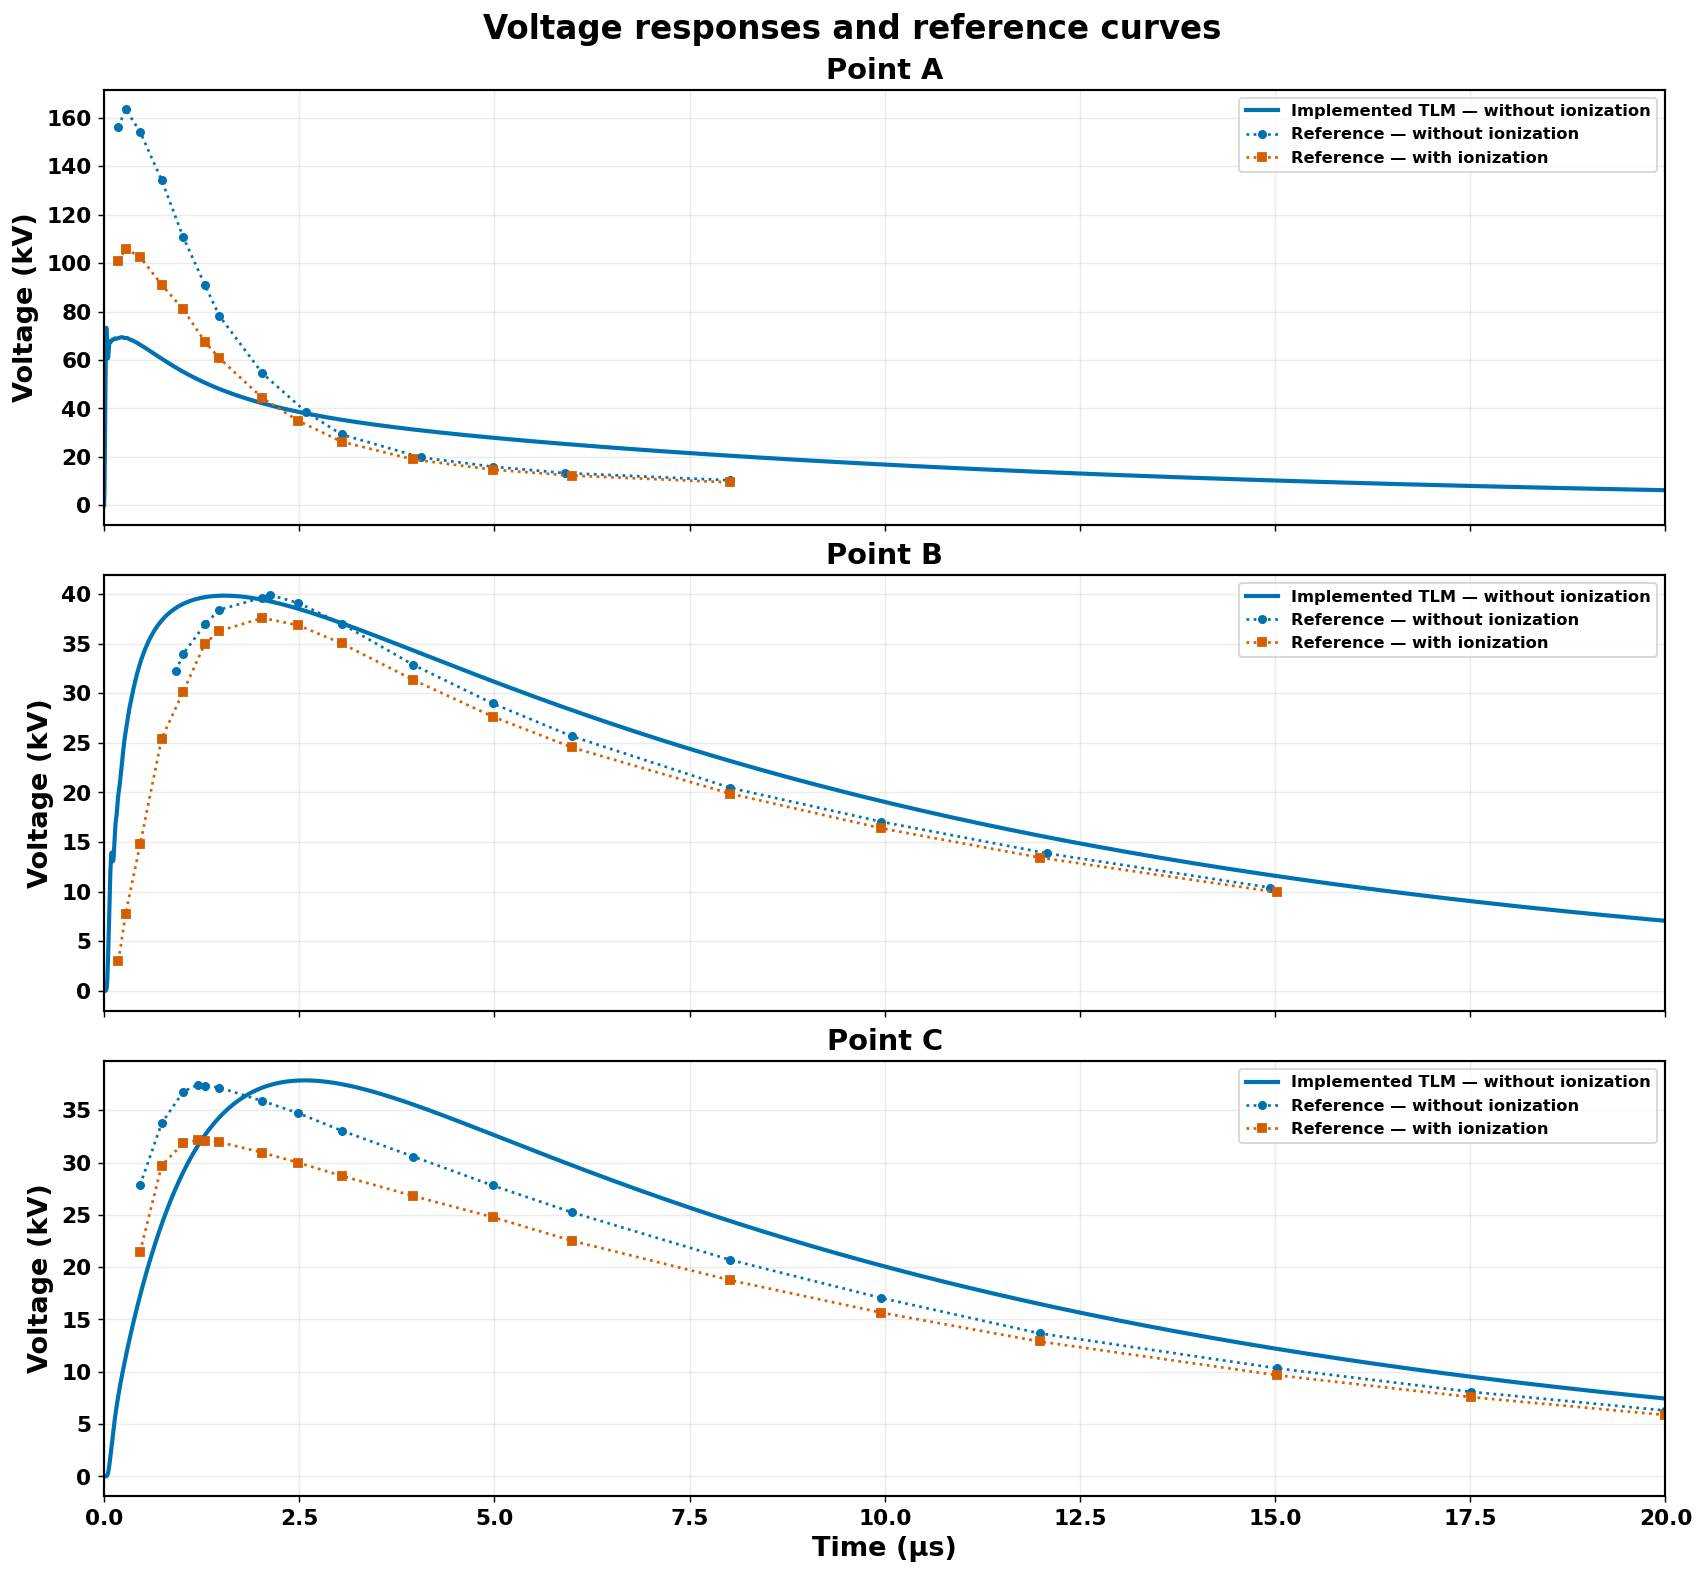

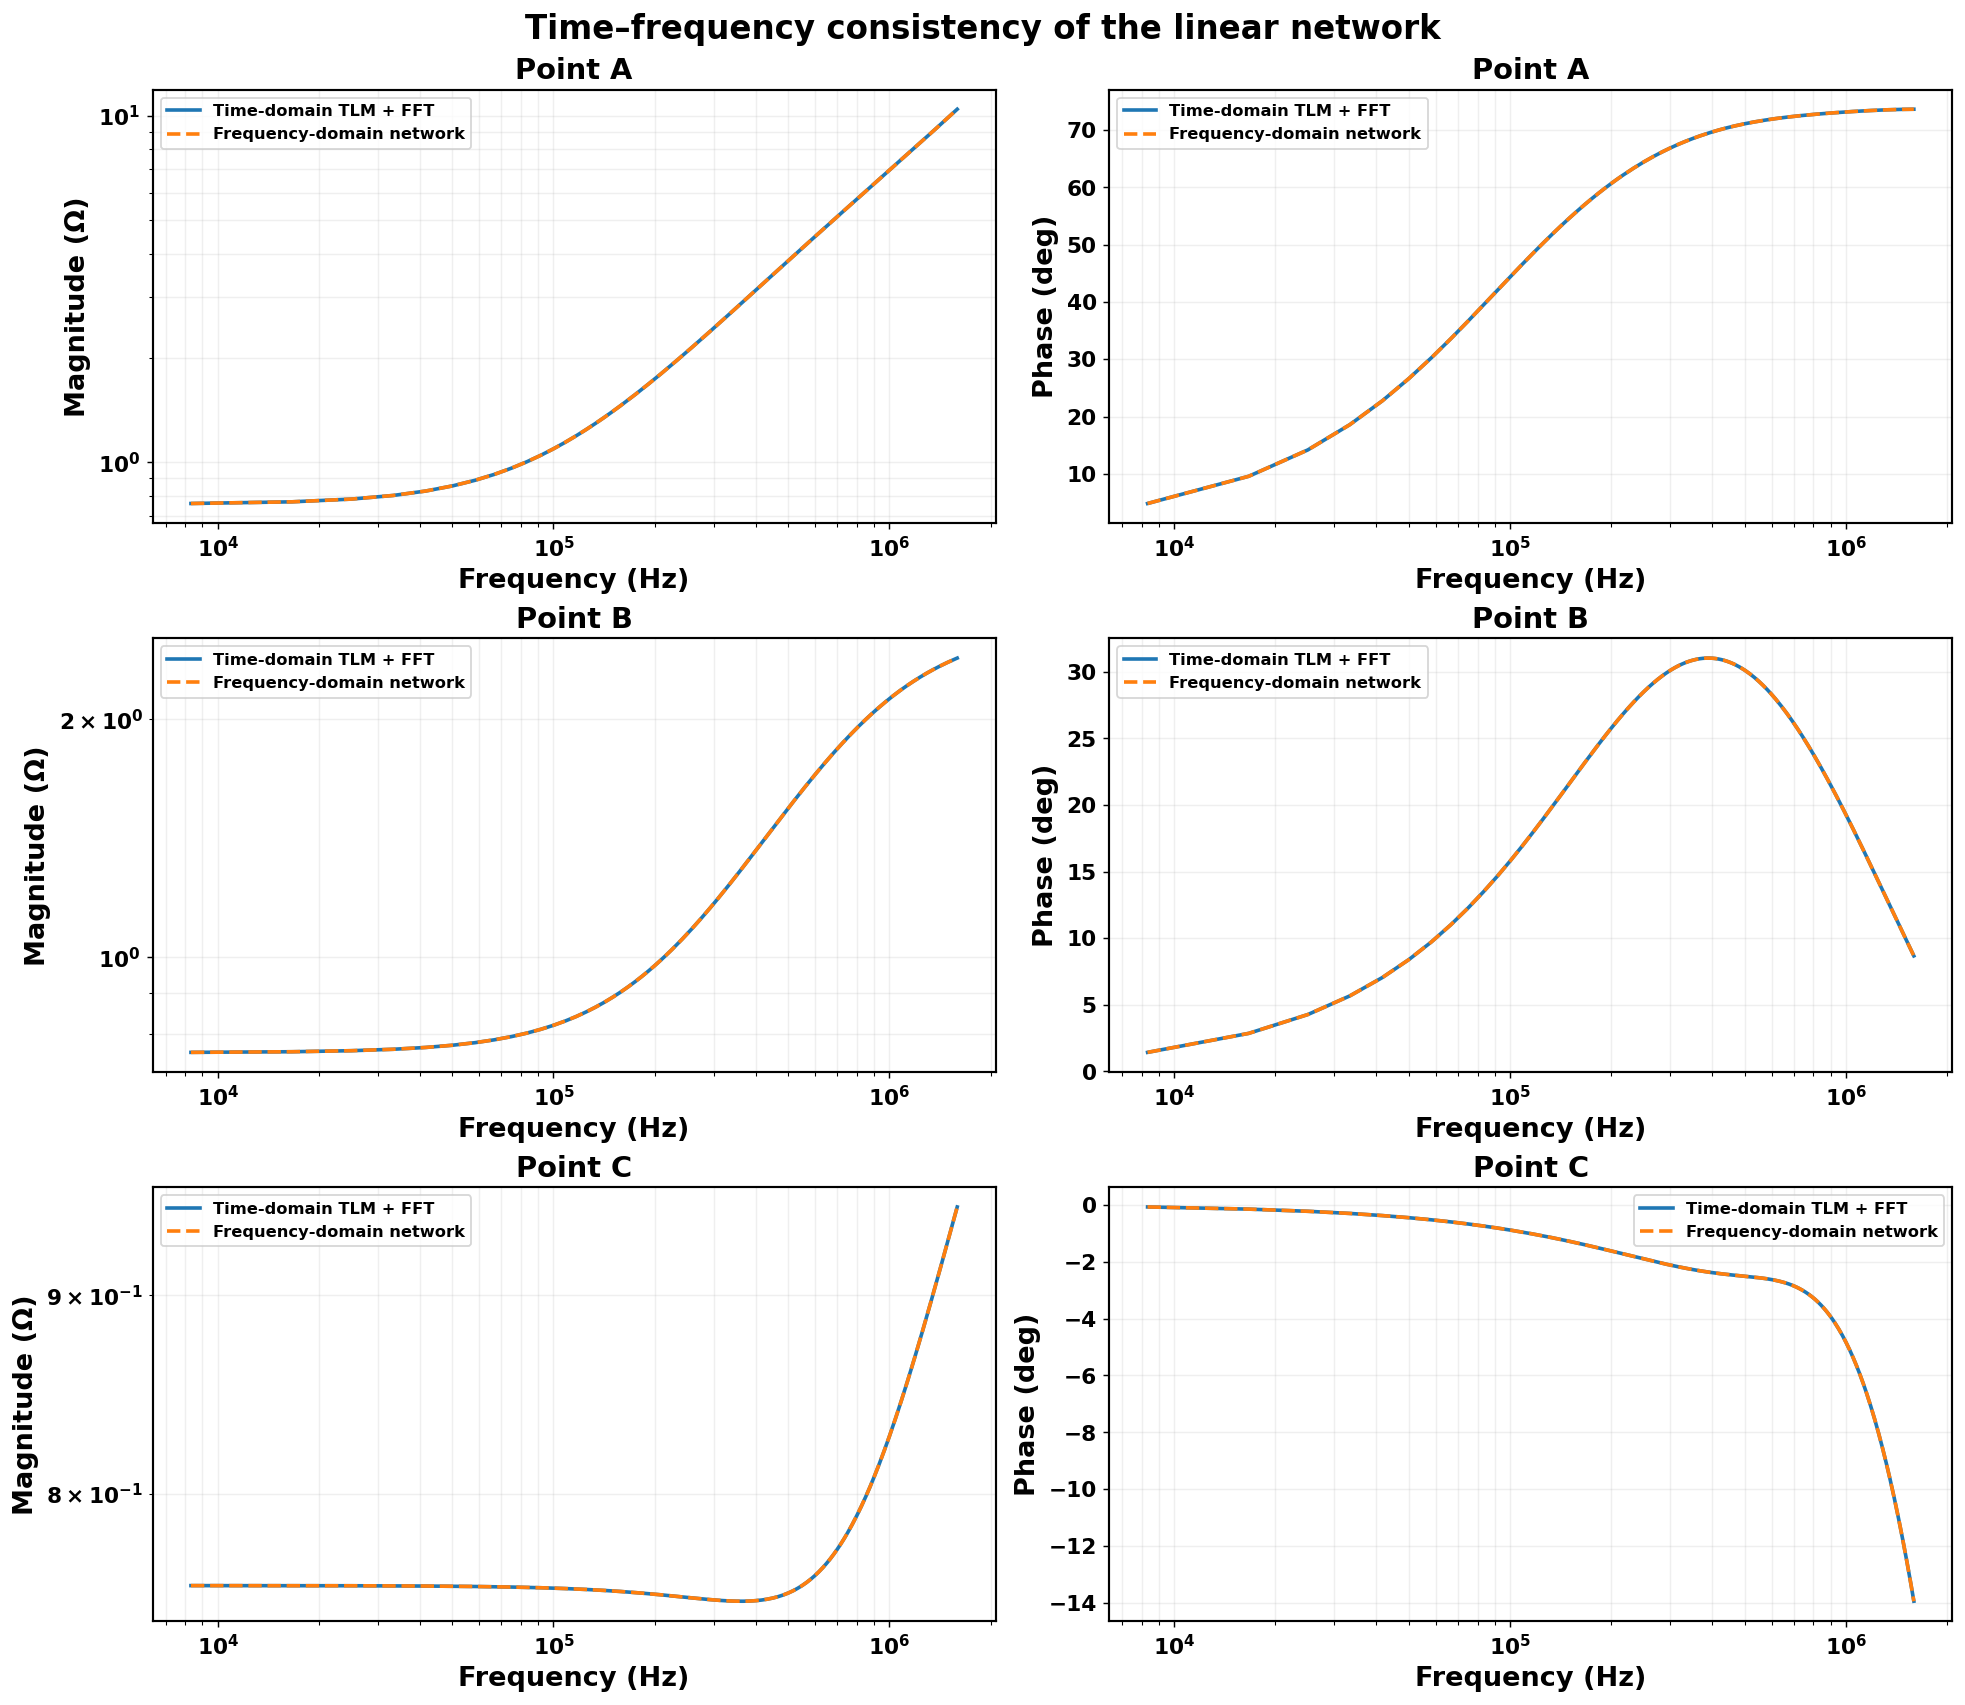

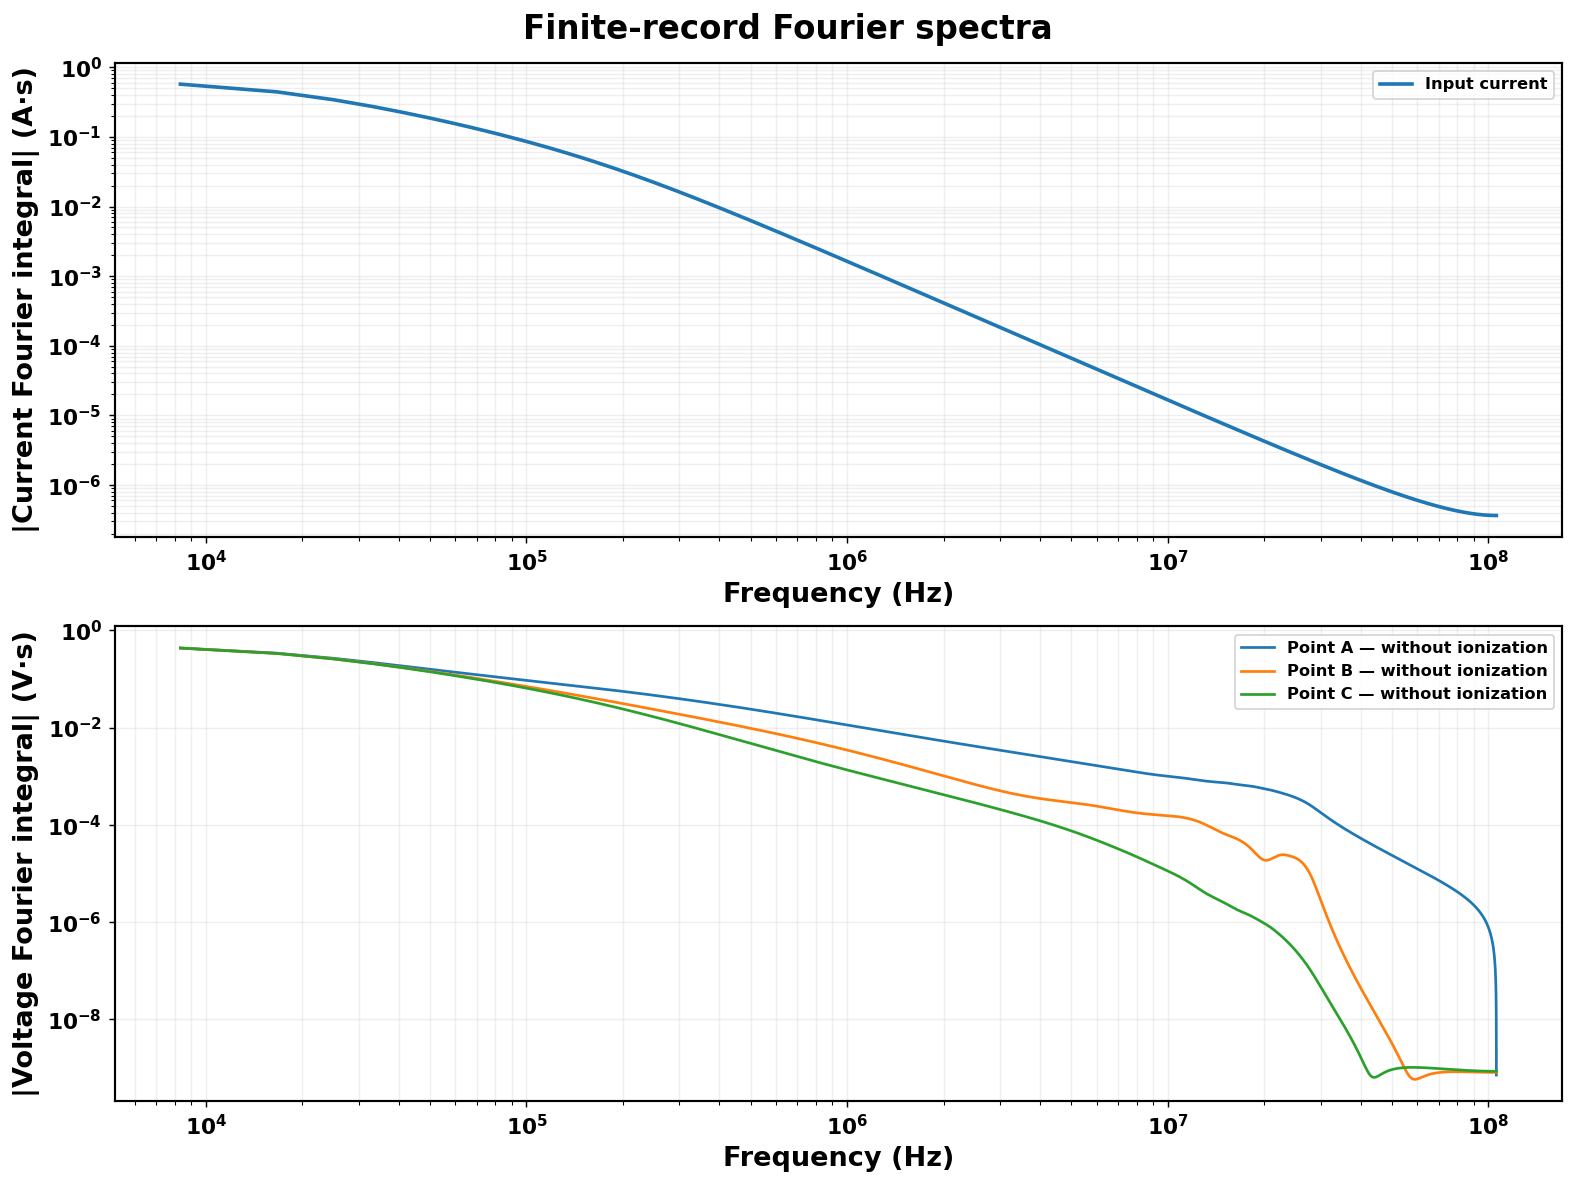

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


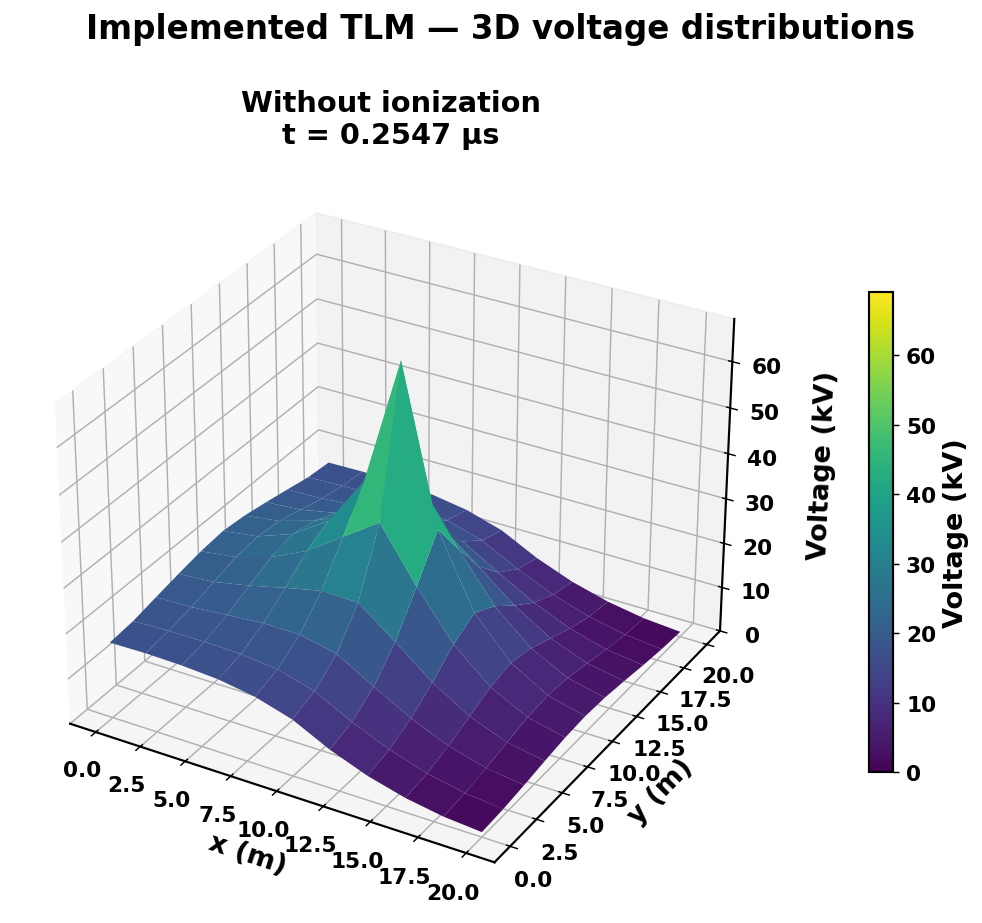

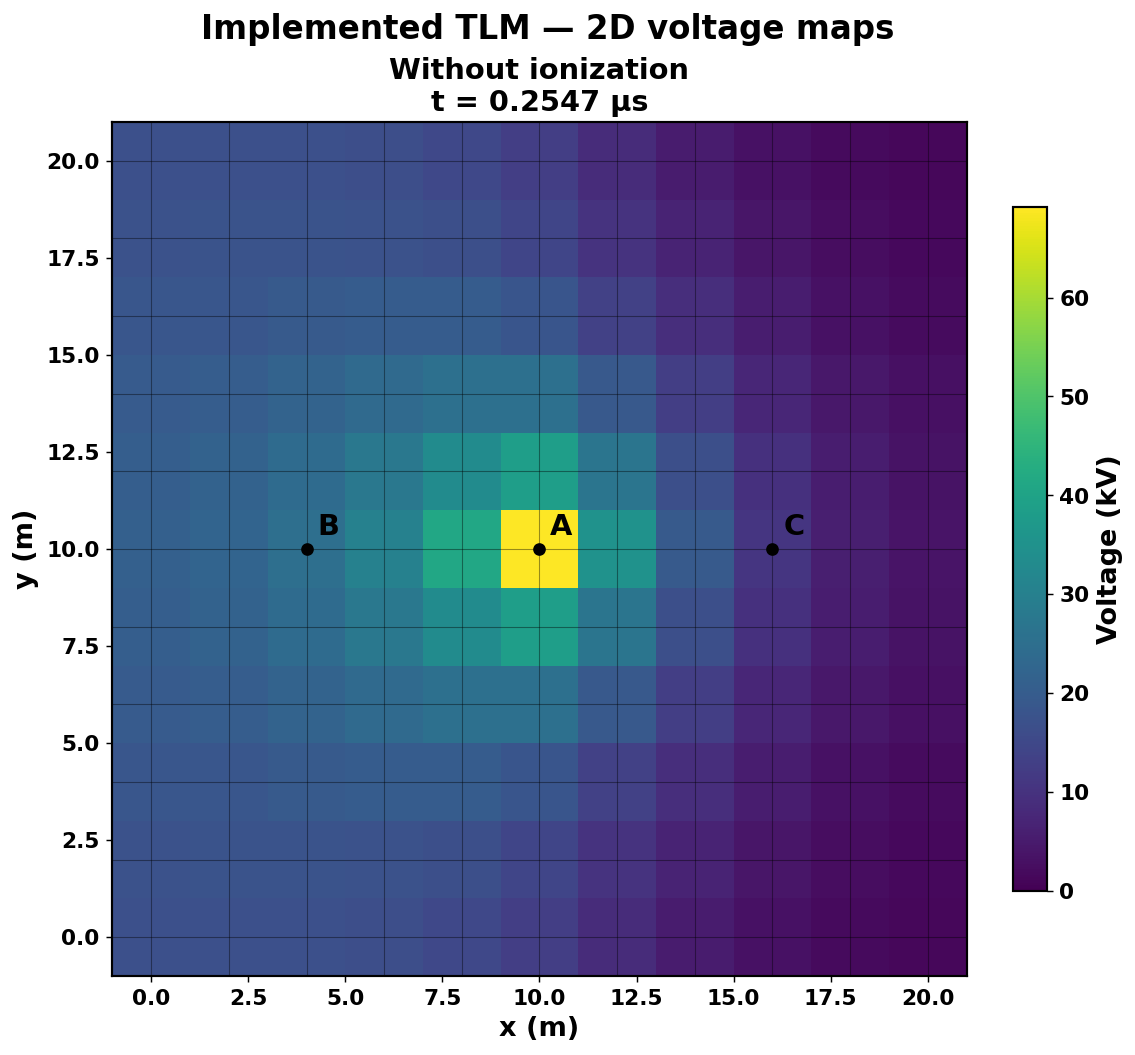

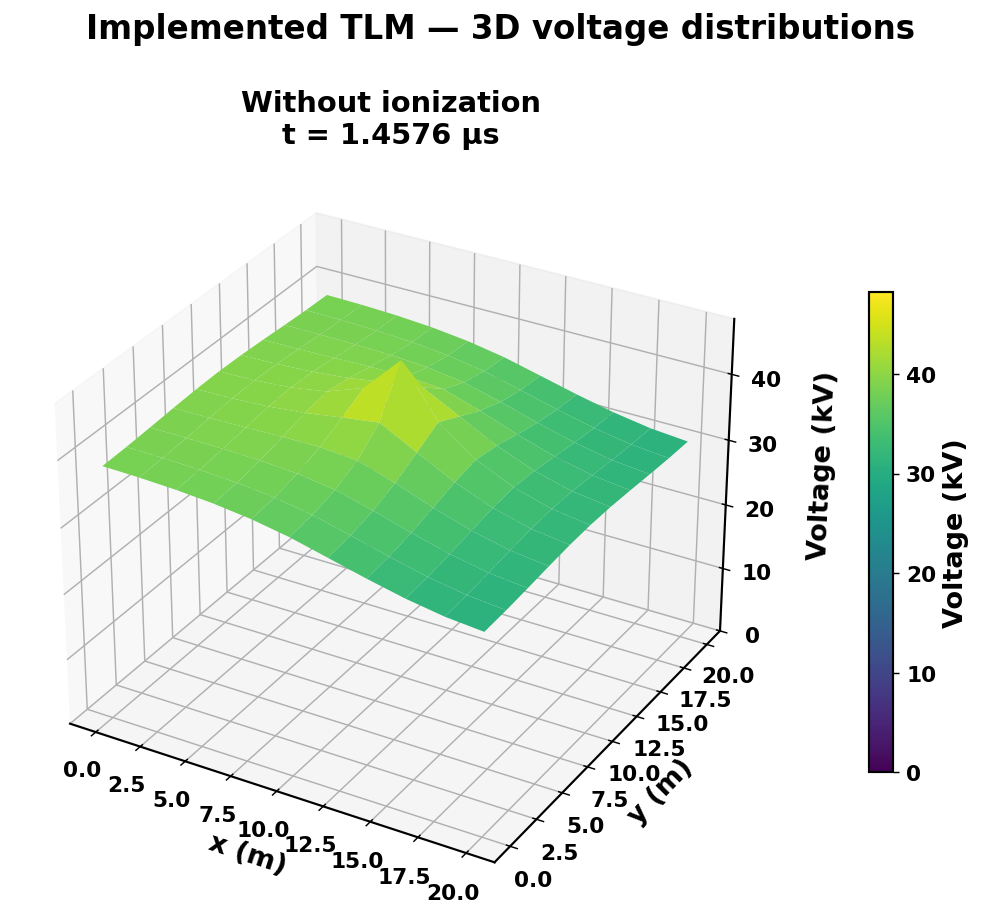

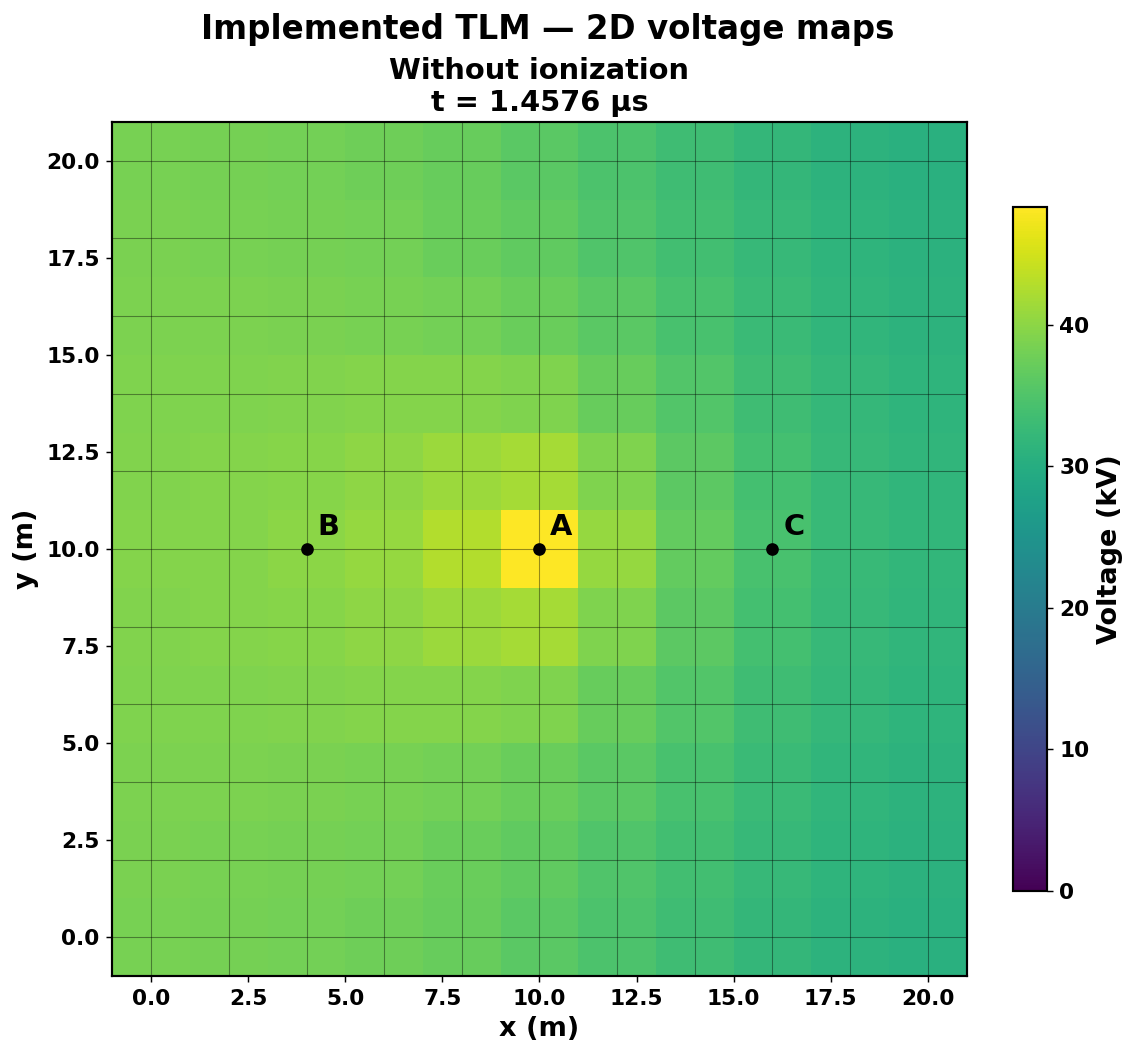

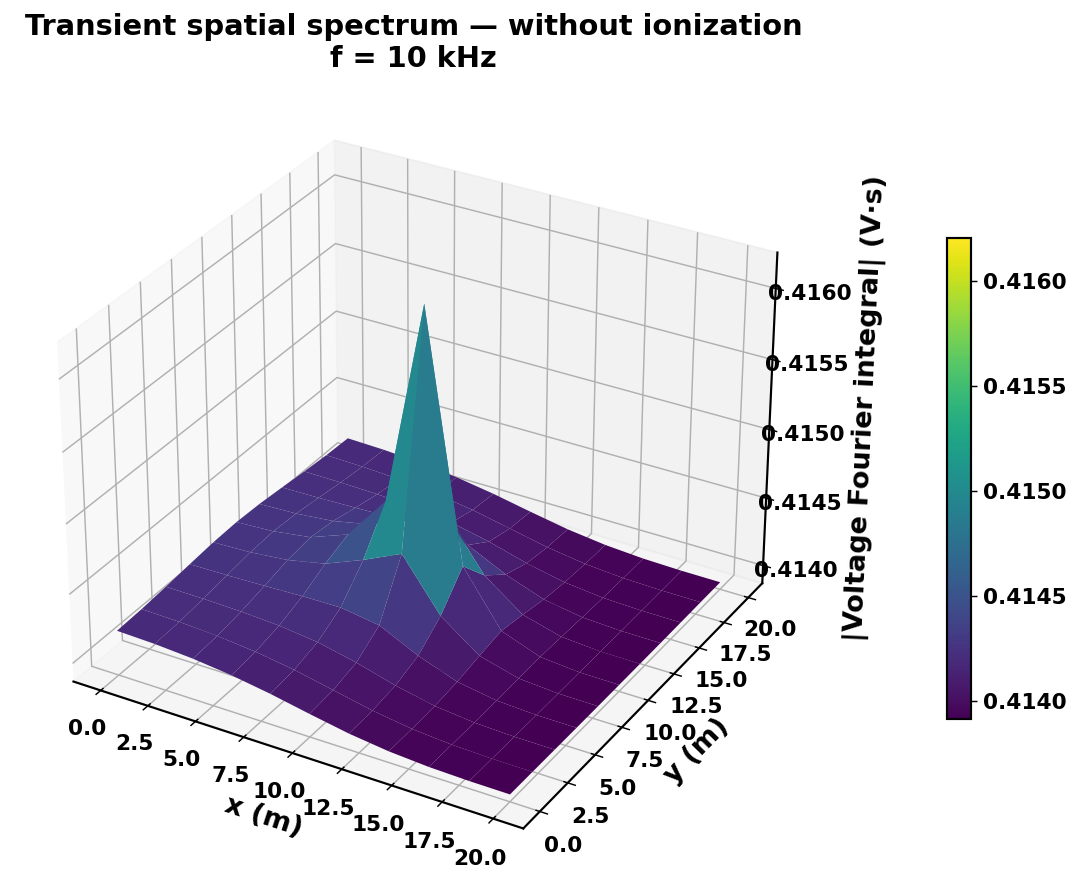

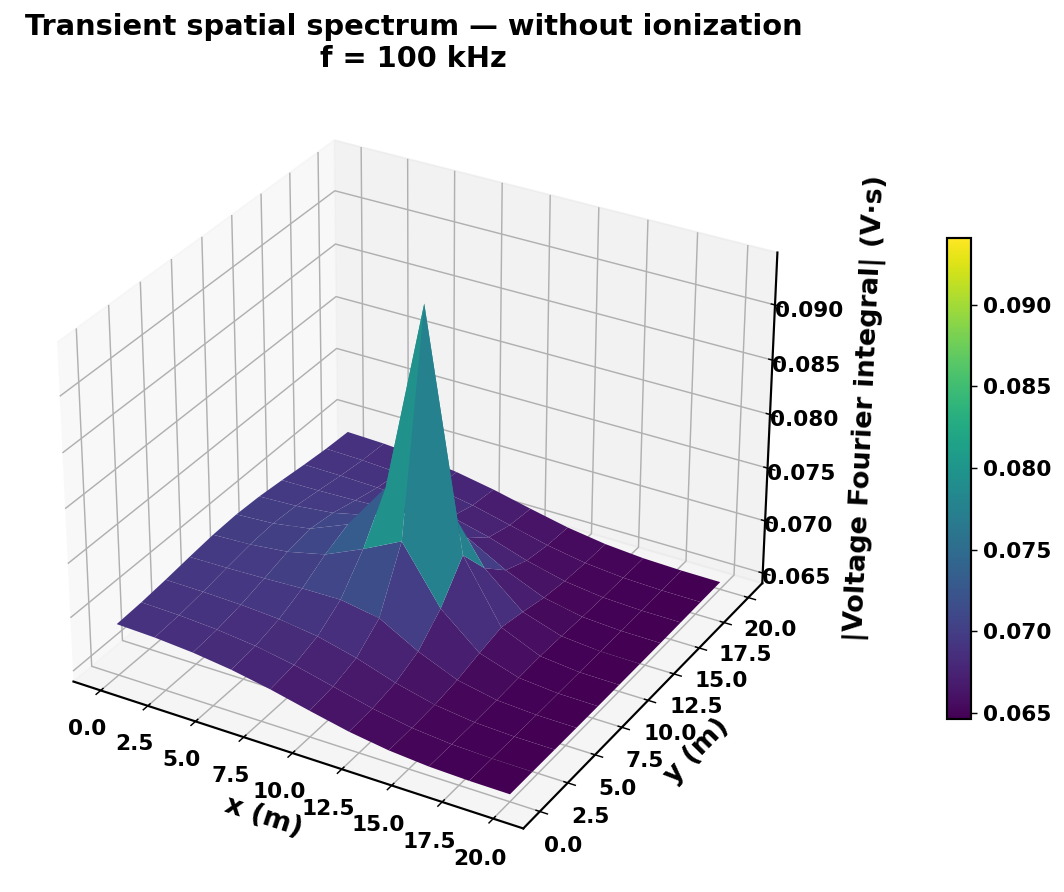

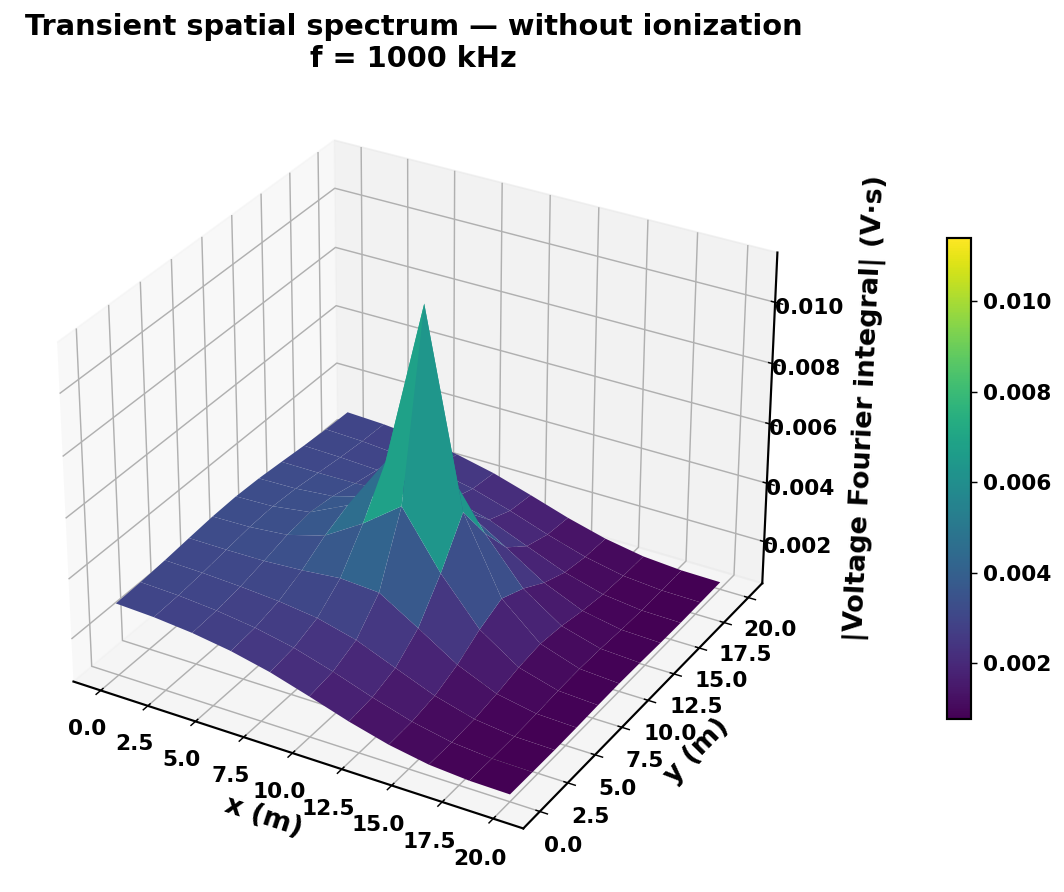

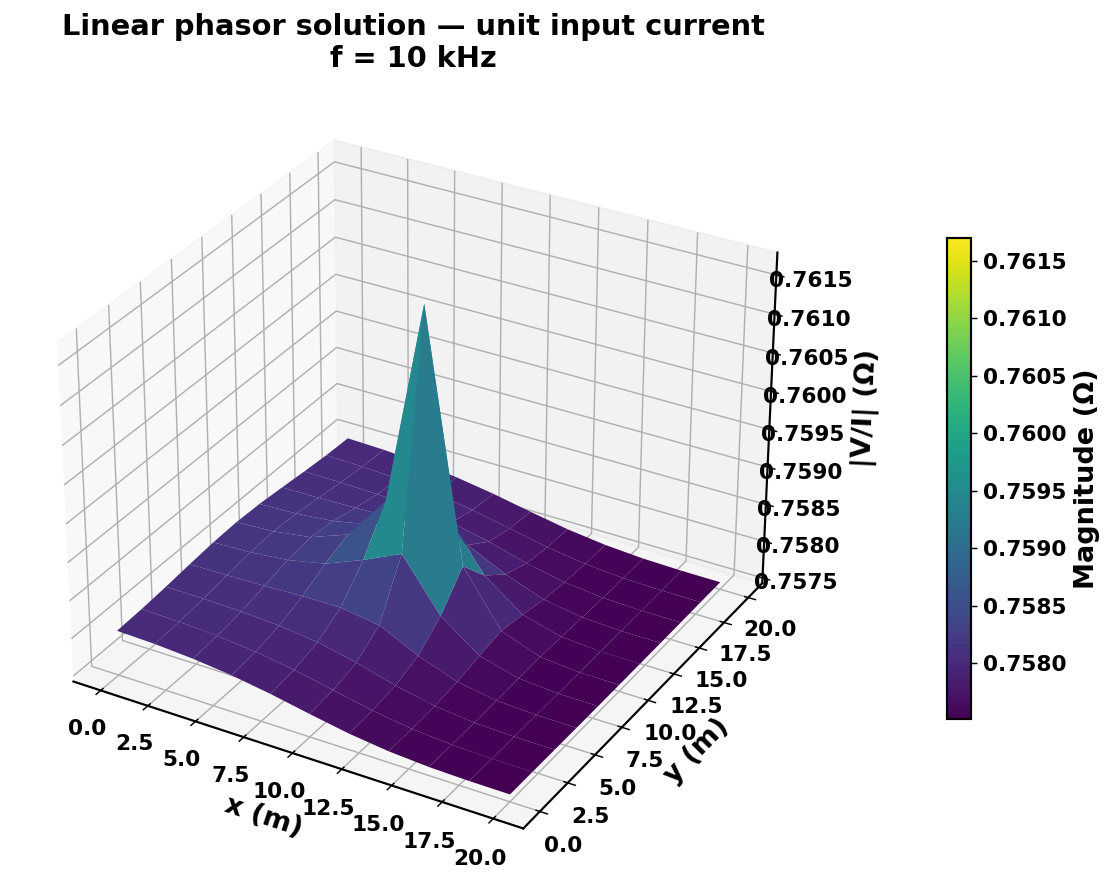

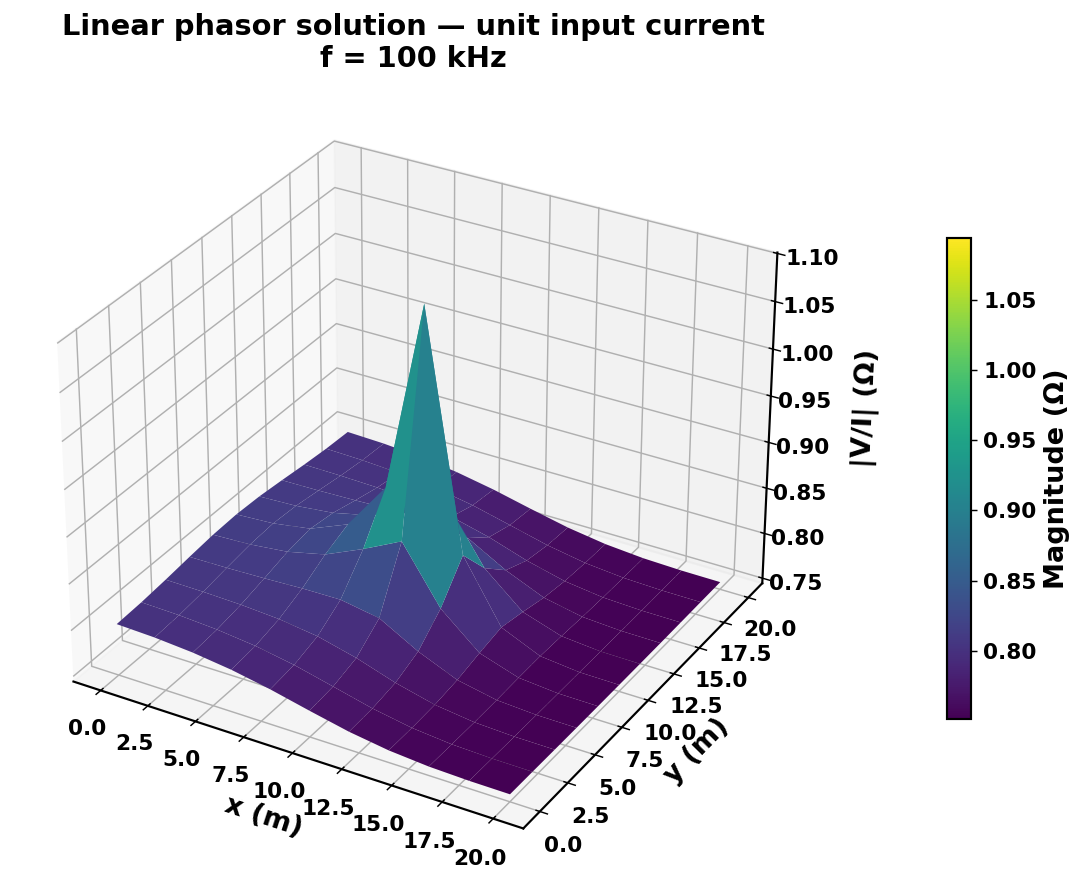

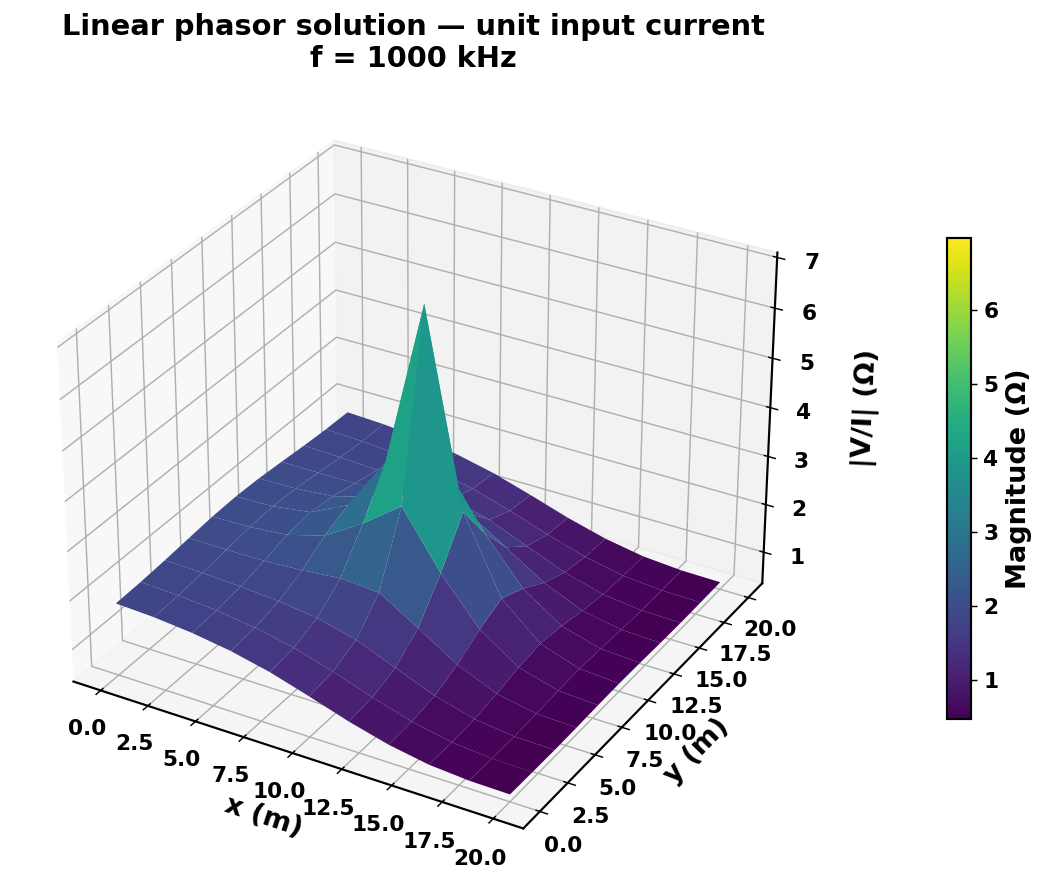


IMPORTANT:
1. The frequency-domain network solver is linear.
2. With ionization, V(f)/I(f) depends on the applied input.
3. Reference curves are approximate graphical digitizations.
4. No reference spectrum is invented from truncated curves.
5. Point A still requires investigation.
6. Spatial convergence and full physical reproduction have not been established.


In [1]:
from dataclasses import dataclass, replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import sparse
from scipy.sparse.linalg import spsolve
from scipy.optimize import least_squares
from IPython.display import display


# ============================================================
# 1. USER CONFIGURATION
# ============================================================

# Numerical value of Ecr was not identified for this case.
# Enter a documented value in V/m to enable ionization.
ECR_DOCUMENTADO = None

# Explicit boundary assumption:
# "open": reflection coefficient +1 at exterior ports.
# "matched": zero incident wave from exterior ports.
BOUNDARY = "open"

# Computational node spacing, not a demonstrated converged mesh.
SPACING_M = 2.0

# The article's table gives 100 ohm m.
# Its case-study text also mentions 200 ohm m.
RHO_RIGHT = 100.0

DURATION_US = 120.0


# ============================================================
# 2. GRAPH STYLE
# ============================================================

BLUE = "#0072B2"
ORANGE = "#D55E00"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 13,
    "font.weight": "bold",
    "axes.labelsize": 15,
    "axes.labelweight": "bold",
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "figure.titlesize": 18,
    "figure.titleweight": "bold",
    "figure.dpi": 130,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "legend.frameon": True,
})


def show_figure(fig):
    for ax in fig.axes:
        labels = list(ax.get_xticklabels())
        labels += list(ax.get_yticklabels())

        if hasattr(ax, "get_zticklabels"):
            labels += list(ax.get_zticklabels())

        for label in labels:
            label.set_fontweight("bold")

        for axis_name in ("xaxis", "yaxis", "zaxis"):
            if hasattr(ax, axis_name):
                axis = getattr(ax, axis_name)
                axis.get_offset_text().set_fontweight("bold")

        legend = ax.get_legend()

        if legend is not None:
            for text in legend.get_texts():
                text.set_fontweight("bold")

    plt.show()
    plt.close(fig)


# ============================================================
# 3. CONSTANTS AND REFERENCE DATA
# ============================================================

EPS0 = 8.8541878128e-12
MU0 = 4 * np.pi * 1e-7

# Rows: A, B, C.
# Columns: without ionization / with ionization.
# A values come from the IPST2019 version.
REFERENCE_PEAKS = np.array([
    [164.9, 107.4],
    [40.0, 37.7],
    [37.4, 32.1],
])

# Approximate digitization of Fig. 8.
# Columns: time (us), current (kA).
SOURCE_REFERENCE = np.array([
    [1.036, 39.6],
    [1.507, 45.9],
    [1.978, 49.1],
    [2.355, 49.8],
    [3.014, 49.6],
    [3.956, 46.9],
    [4.992, 43.1],
    [6.028, 39.1],
    [8.006, 32.1],
    [10.361, 25.5],
    [11.962, 21.7],
    [14.976, 16.1],
    [20.345, 9.4],
    [24.961, 6.0],
    [30.424, 3.5],
    [35.039, 2.2],
    [40.408, 1.4],
    [45.024, 0.8],
])

# Approximate graphical digitizations of IPST Figs. 11–13.
# Columns: time (us), voltage (kV).
# These are not original numerical data.
# Do not extrapolate beyond the extracted intervals.

REFERENCE_VOLTAGES = {
    "A": [
        np.array([
            [.184, 156.362], [.276, 163.541],
            [.461, 154.261], [.737, 134.300],
            [1.014, 110.661], [1.290, 91.051],
            [1.475, 78.268], [2.028, 54.455],
            [2.581, 38.696], [3.041, 29.241],
            [4.055, 19.786], [4.977, 15.934],
            [5.899, 13.307], [8.018, 10.331],
        ]),
        np.array([
            [.184, 100.856], [.276, 105.934],
            [.461, 102.607], [.737, 91.051],
            [1.014, 80.895], [1.290, 67.588],
            [1.475, 60.759], [2.028, 44.300],
            [2.488, 34.844], [3.041, 26.265],
            [3.963, 18.911], [4.977, 14.708],
            [5.991, 12.257], [8.018, 9.455],
        ]),
    ],
    "B": [
        np.array([
            [.922, 32.272], [1.014, 33.981],
            [1.290, 36.932], [1.475, 38.408],
            [2.028, 39.650], [2.120, 39.922],
            [2.488, 39.107], [3.041, 37.010],
            [3.963, 32.854], [4.977, 28.971],
            [5.991, 25.670], [8.018, 20.466],
            [9.954, 17.049], [12.074, 13.864],
            [14.931, 10.408],
        ]),
        np.array([
            [.184, 3.029], [.276, 7.767],
            [.461, 14.757], [.737, 25.437],
            [1.014, 30.175], [1.290, 34.990],
            [1.475, 36.272], [2.028, 37.592],
            [2.488, 36.854], [3.041, 35.029],
            [3.963, 31.340], [4.977, 27.650],
            [5.991, 24.544], [8.018, 19.883],
            [9.954, 16.388], [11.982, 13.437],
            [15.023, 9.942],
        ]),
    ],
    "C": [
        np.array([
            [.461, 27.845], [.737, 33.748],
            [1.014, 36.777], [1.198, 37.437],
            [1.290, 37.359], [1.475, 37.165],
            [2.028, 35.883], [2.488, 34.718],
            [3.041, 33.049], [3.963, 30.563],
            [4.977, 27.806], [5.991, 25.243],
            [8.018, 20.699], [9.954, 17.049],
            [11.982, 13.670], [15.023, 10.330],
            [17.512, 8.078], [20.000, 6.291],
        ]),
        np.array([
            [.461, 21.476], [.737, 29.709],
            [1.014, 31.845], [1.198, 32.117],
            [1.290, 32.039], [1.475, 31.961],
            [2.028, 30.951], [2.488, 29.981],
            [3.041, 28.738], [3.963, 26.796],
            [4.977, 24.777], [5.991, 22.524],
            [8.018, 18.757], [9.954, 15.650],
            [11.982, 12.893], [15.023, 9.670],
            [17.512, 7.573], [20.000, 5.864],
        ]),
    ],
}


# ============================================================
# 4. MODEL CONFIGURATION
# ============================================================

@dataclass(frozen=True)
class Config:
    length: float = 20.0
    spacing: float = 2.0

    rho_left: float = 600.0
    rho_right: float = 100.0

    er_left: float = 6.0
    er_right: float = 12.0

    duration: float = 120e-6
    source_peak: float = 50000.0

    tau_fast: float = 0.98347912e-6
    tau_slow: float = 10.07509478e-6

    boundary: str = "open"
    critical_field: float | None = None

    # Approximate coordinates inferred from the figure.
    point_A: tuple = (10.0, 10.0)
    point_B: tuple = (4.0, 10.0)
    point_C: tuple = (16.0, 10.0)


# ============================================================
# 5. CURRENT SOURCE
# ============================================================

def impulse(t, cfg):
    a = cfg.tau_fast
    b = cfg.tau_slow

    if not 0 < a < b:
        raise ValueError("Require 0 < tau_fast < tau_slow.")

    t = np.asarray(t)

    peak_time = np.log(b / a) / (1 / a - 1 / b)

    normalization = (
        np.exp(-peak_time / b)
        - np.exp(-peak_time / a)
    )

    return (
        cfg.source_peak
        * (np.exp(-t / b) - np.exp(-t / a))
        / normalization
    )


def fit_input_current(cfg):
    # Fits ONLY the input current digitization.
    # Does not use any voltage result or reference voltage.

    def residual(p):
        candidate = replace(
            cfg,
            tau_fast=np.exp(p[0]) * 1e-6,
            tau_slow=np.exp(p[1]) * 1e-6,
        )

        calculated = impulse(
            SOURCE_REFERENCE[:, 0] * 1e-6,
            candidate,
        )

        return (
            calculated - SOURCE_REFERENCE[:, 1] * 1000
        ) / cfg.source_peak

    fit = least_squares(
        residual,
        np.log([1.0, 10.0]),
        bounds=(
            np.log([0.01, 5.0]),
            np.log([4.0, 30.0]),
        ),
    )

    return replace(
        cfg,
        tau_fast=np.exp(fit.x[0]) * 1e-6,
        tau_slow=np.exp(fit.x[1]) * 1e-6,
    )


# ============================================================
# 6. BUILD THE TLM NETWORK
# ============================================================

def build_model(cfg):
    if cfg.boundary not in ("open", "matched"):
        raise ValueError("Unknown boundary condition.")

    if min(
        cfg.length,
        cfg.spacing,
        cfg.rho_left,
        cfg.rho_right,
        cfg.er_left,
        cfg.er_right,
    ) <= 0:
        raise ValueError("Parameters must be positive.")

    if min(cfg.er_left, cfg.er_right) < 1:
        raise ValueError("This implementation requires er >= 1.")

    n = round(cfg.length / cfg.spacing) + 1

    if not np.isclose((n - 1) * cfg.spacing, cfg.length):
        raise ValueError("Spacing must divide domain length.")

    x = np.arange(n) * cfg.spacing
    X, Y_grid = np.meshgrid(x, x)

    # Interface convention:
    # A at x=10 m belongs to region 1.
    left = X <= cfg.length / 2 + 1e-12

    rho = np.where(left, cfg.rho_left, cfg.rho_right)
    er = np.where(left, cfg.er_left, cfg.er_right)

    # EPSR Eqs. (3)–(6): free-space background.
    Ld = MU0
    Cd = EPS0 / 2

    Z_line = np.sqrt(Ld / Cd)
    Y_line = 1 / Z_line

    dt = cfg.spacing * np.sqrt(Ld * Cd)

    # EPSR Eqs. (7)–(8).
    # All admittances are in physical siemens.
    Y_stub = 4 * Y_line * (er - 1)
    G_initial = cfg.spacing / rho

    locations = []

    for point in (cfg.point_A, cfg.point_B, cfg.point_C):
        column = int(np.argmin(np.abs(x - point[0])))
        row = int(np.argmin(np.abs(x - point[1])))

        if not np.allclose([x[column], x[row]], point):
            raise ValueError(
                "An observation point is not on the selected grid."
            )

        locations.append((row, column))

    # Neighbor adjacency for the independent frequency solution.
    size = n * n
    ids = np.arange(size).reshape(n, n)

    first = np.r_[
        ids[:, :-1].ravel(),
        ids[:-1, :].ravel(),
    ]

    second = np.r_[
        ids[:, 1:].ravel(),
        ids[1:, :].ravel(),
    ]

    adjacency = sparse.coo_matrix(
        (
            np.ones(2 * len(first)),
            (
                np.r_[first, second],
                np.r_[second, first],
            ),
        ),
        shape=(size, size),
    ).tocsr()

    degree = np.asarray(
        adjacency.sum(axis=1)
    ).ravel()

    return {
        "cfg": cfg,
        "n": n,
        "x": x,
        "X": X,
        "Y": Y_grid,
        "rho": rho,
        "Yline": Y_line,
        "Ys": Y_stub,
        "G0": G_initial,
        "Z": Z_line,
        "dt": dt,
        "locations": locations,
        "adj": adjacency,
        "degree": degree,
    }


# ============================================================
# 7. IONIZATION CONDUCTANCE
# ============================================================

def ionization_ready(cfg):
    return cfg.critical_field is not None


def ion_conductance(model, voltage, previous_conductance):
    cfg = model["cfg"]

    if not ionization_ready(cfg):
        raise ValueError("A documented Ecr is required.")

    if cfg.critical_field <= 0:
        raise ValueError("Ecr must be positive.")

    rho = model["rho"]

    # EPSR Eq. (16).
    # The result is a fraction:
    # 0.07508 corresponds to 7.508%.
    residual_fraction = (
        8.645e-7 * rho**2
        - 6.924e-4 * rho
        + 0.1793
    )

    if np.any(
        (residual_fraction < 0)
        | (residual_fraction >= 1)
    ):
        raise ValueError(
            "Residual-resistivity fit outside physical range."
        )

    # Published TM equivalence, Eq. (3).
    # Not the spatial gradient of voltage.
    electric_field = np.abs(voltage) / cfg.spacing

    active = electric_field >= cfg.critical_field

    # Explicit local closure:
    # J(k) = sigma(k) * |E(k)|.
    # The article does not fully specify its numerical J estimator.
    sigma_previous = previous_conductance / cfg.spacing
    current_density = sigma_previous * electric_field

    critical_density = cfg.critical_field / rho

    # EPSR Eq. (17).
    sigma_nonlinear = (
        np.sqrt(1 + current_density / critical_density)
        / (rho * (1 - residual_fraction))
    )

    # EPSR Eq. (18).
    updated = np.where(
        active,
        sigma_nonlinear * cfg.spacing,
        model["G0"],
    )

    return updated, active


# ============================================================
# 8. CONNECTION STEP
# ============================================================

def connect(reflected, boundary):
    # Port order: W, E, S, N.
    incident_next = np.zeros_like(reflected)

    incident_next[0, :, 1:] = reflected[1, :, :-1]
    incident_next[1, :, :-1] = reflected[0, :, 1:]
    incident_next[2, 1:, :] = reflected[3, :-1, :]
    incident_next[3, :-1, :] = reflected[2, 1:, :]

    if boundary == "open":
        # Reflection returns to the SAME exterior port.
        incident_next[0, :, 0] = reflected[0, :, 0]
        incident_next[1, :, -1] = reflected[1, :, -1]
        incident_next[2, 0, :] = reflected[2, 0, :]
        incident_next[3, -1, :] = reflected[3, -1, :]

    # With matched boundaries, exterior incident waves remain zero.
    return incident_next


# ============================================================
# 9. TIME-DOMAIN SOLVER
# ============================================================

def simulate(
    model,
    ionization=False,
    snapshots_us=(0.2542, 1.456),
    frequencies=(1e4, 1e5, 1e6),
):
    cfg = model["cfg"]

    if ionization and not ionization_ready(cfg):
        raise ValueError("Missing documented Ecr.")

    dt = model["dt"]
    n = model["n"]

    Y_line = model["Yline"]
    Y_stub = model["Ys"]

    count = int(np.ceil(cfg.duration / dt)) + 1

    time = np.arange(count) * dt
    current = impulse(time, cfg)

    incident = np.zeros((4, n, n))
    stub_incident = np.zeros((n, n))
    conductance = model["G0"].copy()

    voltages = np.zeros((count, 3))
    active_count = np.zeros(count, dtype=int)

    capture_steps = {}

    for requested in snapshots_us:
        index = int(round(requested * 1e-6 / dt))

        if not 0 <= index < count:
            raise ValueError("Snapshot outside simulation range.")

        capture_steps[index] = requested

    snapshots = {}

    frequencies = np.asarray(frequencies, dtype=float)

    field_spectrum = np.zeros(
        (len(frequencies), n, n),
        dtype=complex,
    )

    for k in range(count):
        numerator = (
            2 * Y_line * incident.sum(axis=0)
            + 2 * Y_stub * stub_incident
        )

        # Physical Norton-current injection.
        # No fitted amplitude multiplier.
        numerator[model["locations"][0]] += current[k]

        voltage = numerator / (
            4 * Y_line + Y_stub + conductance
        )

        voltages[k] = [
            voltage[location]
            for location in model["locations"]
        ]

        if k in capture_steps:
            requested = capture_steps[k]

            snapshots[requested] = (
                time[k],
                voltage.copy(),
            )

        if frequencies.size:
            weights = np.exp(
                -2j * np.pi * frequencies * time[k]
            )

            field_spectrum += (
                weights[:, None, None]
                * voltage[None, :, :]
                * dt
            )

        if ionization:
            conductance, active = ion_conductance(
                model,
                voltage,
                conductance,
            )

            active_count[k] = active.sum()

        reflected = voltage[None, :, :] - incident

        incident = connect(
            reflected,
            cfg.boundary,
        )

        # Open capacitive stub:
        # incident(k+1) = reflected(k).
        stub_incident = voltage - stub_incident

    if not np.isfinite(voltages).all():
        raise FloatingPointError(
            "Non-finite time-domain solution."
        )

    return {
        "t": time,
        "I": current,
        "V": voltages,
        "snapshots": snapshots,
        "frequencies": frequencies,
        "field_spectrum": field_spectrum,
        "active_count": active_count,
    }


# ============================================================
# 10. INDEPENDENT LINEAR FREQUENCY-DOMAIN SOLVER
# ============================================================
# Solves the SAME discrete network directly in frequency.
# It is not simply the FFT of the time-domain output.
#
# Elimination of incident waves yields branch admittances:
#   Y*coth(s*dt)
#   -Y*csch(s*dt)
# and open-stub admittance:
#   Ys*tanh(s*dt/2)
#
# Multiplication by sinh(s*dt) avoids division near DC.
# Unit input current: output values have units V/A = ohm.
# ============================================================

def frequency_solution(
    model,
    frequencies,
    return_fields=False,
):
    frequencies = np.atleast_1d(
        frequencies
    ).astype(float)

    n = model["n"]
    size = n * n

    Y_line = model["Yline"]
    degree = model["degree"]
    missing_ports = 4 - degree

    Y_stub = model["Ys"].ravel()
    conductance = model["G0"].ravel()
    dt = model["dt"]

    responses = np.zeros(
        (len(frequencies), 3),
        dtype=complex,
    )

    fields = None

    if return_fields:
        fields = np.zeros(
            (len(frequencies), n, n),
            dtype=complex,
        )

    source_index = np.ravel_multi_index(
        model["locations"][0],
        (n, n),
    )

    observed_indices = [
        np.ravel_multi_index(location, (n, n))
        for location in model["locations"]
    ]

    for k, frequency in enumerate(frequencies):
        if frequency < 0 or frequency > 0.5 / dt:
            raise ValueError(
                "Frequency outside the Nyquist interval."
            )

        if frequency == 0:
            leakage = conductance.sum()

            if model["cfg"].boundary == "matched":
                leakage += Y_line * missing_ports.sum()

            voltage = np.full(
                size,
                1 / leakage,
                dtype=complex,
            )

        else:
            z = 2j * np.pi * frequency * dt

            sinh_z = np.sinh(z)
            cosh_z = np.cosh(z)

            diagonal = (
                conductance * sinh_z
                + Y_stub * (cosh_z - 1)
                + Y_line * degree * cosh_z
            )

            if model["cfg"].boundary == "open":
                diagonal += (
                    Y_line
                    * missing_ports
                    * (cosh_z - 1)
                )
            else:
                diagonal += (
                    Y_line
                    * missing_ports
                    * sinh_z
                )

            matrix = (
                sparse.diags(
                    diagonal,
                    format="csc",
                )
                - Y_line * model["adj"].tocsc()
            )

            rhs = np.zeros(size, dtype=complex)
            rhs[source_index] = sinh_z

            voltage = spsolve(matrix, rhs)

        responses[k] = voltage[observed_indices]

        if return_fields:
            fields[k] = voltage.reshape(n, n)

    if return_fields:
        return responses, fields

    return responses


# ============================================================
# 11. FOURIER ANALYSIS
# ============================================================

def spectrum(run):
    dt = run["t"][1] - run["t"][0]

    frequencies = np.fft.rfftfreq(
        len(run["t"]),
        dt,
    )

    # Finite-record Fourier integrals.
    current_spectrum = dt * np.fft.rfft(run["I"])
    voltage_spectrum = dt * np.fft.rfft(
        run["V"],
        axis=0,
    )

    # Avoid divisions where the input spectrum is too small.
    valid = (
        (frequencies > 0)
        & (
            np.abs(current_spectrum)
            > 1e-3 * np.abs(current_spectrum).max()
        )
    )

    ratio = np.full(
        voltage_spectrum.shape,
        np.nan + 1j * np.nan,
    )

    ratio[valid] = (
        voltage_spectrum[valid]
        / current_spectrum[valid, None]
    )

    return {
        "f": frequencies,
        "I": current_spectrum,
        "V": voltage_spectrum,
        "ratio": ratio,
        "valid": valid,
    }


# ============================================================
# 12. CURRENT COMPARISON
# ============================================================

def plot_current(linear):
    fig, axes = plt.subplots(
        1, 2,
        figsize=(16, 5),
        layout="constrained",
    )

    for ax in axes:
        ax.plot(
            linear["t"] * 1e6,
            linear["I"] / 1000,
            color=BLUE,
            linewidth=2.3,
            label="Implemented input",
        )

        ax.plot(
            SOURCE_REFERENCE[:, 0],
            SOURCE_REFERENCE[:, 1],
            "o--",
            color=ORANGE,
            markersize=4,
            label="Reference — digitized",
        )

        ax.set_xlabel("Time (µs)")
        ax.set_ylabel("Current (kA)")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=10)

    axes[0].set_xlim(0, 60)
    axes[0].set_title("Full time window")

    axes[1].set_xlim(0, 10)
    axes[1].set_title("Front and peak detail")

    fig.suptitle("Input current comparison")
    show_figure(fig)


# ============================================================
# 13. VOLTAGE COMPARISON
# ============================================================

def plot_voltages(linear, nonlinear=None):
    fig, axes = plt.subplots(
        3, 1,
        figsize=(13, 12),
        sharex=True,
        layout="constrained",
    )

    for j, ax in enumerate(axes):
        point = "ABC"[j]

        ax.plot(
            linear["t"] * 1e6,
            linear["V"][:, j] / 1000,
            color=BLUE,
            linewidth=2.3,
            label="Implemented TLM — without ionization",
        )

        if nonlinear is not None:
            ax.plot(
                nonlinear["t"] * 1e6,
                nonlinear["V"][:, j] / 1000,
                color=ORANGE,
                linewidth=2.3,
                label="Implemented TLM — with ionization",
            )

        for ref, condition, color, marker in zip(
            REFERENCE_VOLTAGES[point],
            ["without ionization", "with ionization"],
            [BLUE, ORANGE],
            ["o", "s"],
        ):
            ax.plot(
                ref[:, 0],
                ref[:, 1],
                linestyle=":",
                marker=marker,
                markersize=4,
                color=color,
                label=f"Reference — {condition}",
            )

        ax.set_title(f"Point {point}")
        ax.set_ylabel("Voltage (kV)")
        ax.set_xlim(0, 20)
        ax.grid(alpha=0.25)
        ax.legend(fontsize=9)

    axes[-1].set_xlabel("Time (µs)")

    fig.suptitle("Voltage responses and reference curves")
    show_figure(fig)


# ============================================================
# 14. FREQUENCY RESPONSE COMPARISON
# ============================================================

def plot_frequency_responses(model, linear, nonlinear=None):
    spec = spectrum(linear)

    mask = (
        spec["valid"]
        & (spec["f"] <= 3e6)
    )

    frequencies = spec["f"][mask]

    direct_response = frequency_solution(
        model,
        frequencies,
    )

    nonlinear_spec = (
        spectrum(nonlinear)
        if nonlinear is not None
        else None
    )

    fig, axes = plt.subplots(
        3, 2,
        figsize=(15, 13),
        layout="constrained",
    )

    for j in range(3):
        axes[j, 0].loglog(
            frequencies,
            np.abs(spec["ratio"][mask, j]),
            linewidth=2,
            label="Time-domain TLM + FFT",
        )

        axes[j, 0].loglog(
            frequencies,
            np.abs(direct_response[:, j]),
            "--",
            linewidth=2,
            label="Frequency-domain network",
        )

        axes[j, 1].semilogx(
            frequencies,
            np.angle(spec["ratio"][mask, j], deg=True),
            linewidth=2,
            label="Time-domain TLM + FFT",
        )

        axes[j, 1].semilogx(
            frequencies,
            np.angle(direct_response[:, j], deg=True),
            "--",
            linewidth=2,
            label="Frequency-domain network",
        )

        if nonlinear_spec is not None:
            mask_nl = (
                nonlinear_spec["valid"]
                & (nonlinear_spec["f"] <= 3e6)
            )

            axes[j, 0].loglog(
                nonlinear_spec["f"][mask_nl],
                np.abs(
                    nonlinear_spec["ratio"][mask_nl, j]
                ),
                ":",
                label="Nonlinear V/I — input dependent",
            )

            axes[j, 1].semilogx(
                nonlinear_spec["f"][mask_nl],
                np.angle(
                    nonlinear_spec["ratio"][mask_nl, j],
                    deg=True,
                ),
                ":",
                label="Nonlinear V/I — input dependent",
            )

        axes[j, 0].set_ylabel("Magnitude (Ω)")
        axes[j, 1].set_ylabel("Phase (deg)")

        for ax in axes[j]:
            ax.set_title(f"Point {'ABC'[j]}")
            ax.set_xlabel("Frequency (Hz)")
            ax.grid(which="both", alpha=0.2)
            ax.legend(fontsize=9)

    fig.suptitle("Time–frequency consistency of the linear network")
    show_figure(fig)


# ============================================================
# 15. CURRENT AND VOLTAGE SPECTRA
# ============================================================

def plot_spectra(linear, nonlinear=None):
    spec = spectrum(linear)
    positive = spec["f"] > 0

    fig, axes = plt.subplots(
        2, 1,
        figsize=(12, 9),
        layout="constrained",
    )

    axes[0].loglog(
        spec["f"][positive],
        np.abs(spec["I"][positive]),
        linewidth=2,
        label="Input current",
    )

    for j in range(3):
        axes[1].loglog(
            spec["f"][positive],
            np.abs(spec["V"][positive, j]),
            label=f"Point {'ABC'[j]} — without ionization",
        )

    if nonlinear is not None:
        spec_nl = spectrum(nonlinear)
        positive_nl = spec_nl["f"] > 0

        for j in range(3):
            axes[1].loglog(
                spec_nl["f"][positive_nl],
                np.abs(spec_nl["V"][positive_nl, j]),
                "--",
                label=f"Point {'ABC'[j]} — with ionization",
            )

    axes[0].set_ylabel("|Current Fourier integral| (A·s)")
    axes[1].set_ylabel("|Voltage Fourier integral| (V·s)")

    for ax in axes:
        ax.set_xlabel("Frequency (Hz)")
        ax.grid(which="both", alpha=0.2)
        ax.legend(fontsize=9)

    fig.suptitle("Finite-record Fourier spectra")
    show_figure(fig)


# ============================================================
# 16. TIME-DOMAIN SPATIAL FIGURES
# ============================================================

def plot_spatial_time(model, linear, nonlinear=None):
    cases = [
        ("Without ionization", linear),
    ]

    if nonlinear is not None:
        cases.append(
            ("With ionization", nonlinear)
        )

    for requested_time in linear["snapshots"]:
        fields = [
            run["snapshots"][requested_time][1] / 1000
            for _, run in cases
        ]

        vmin = min(
            0.0,
            min(float(field.min()) for field in fields),
        )

        vmax = max(
            float(field.max()) for field in fields
        )

        vmax = max(vmax, vmin + 1e-12)

        # 3D surfaces.
        fig = plt.figure(
            figsize=(10 * len(cases), 8),
            layout="constrained",
        )

        for j, (name, run) in enumerate(cases):
            actual_time, _ = run["snapshots"][requested_time]

            ax = fig.add_subplot(
                1, len(cases), j + 1,
                projection="3d",
            )

            surface = ax.plot_surface(
                model["X"],
                model["Y"],
                fields[j],
                cmap="viridis",
                vmin=vmin,
                vmax=vmax,
                linewidth=0,
            )

            ax.set_xlabel("x (m)")
            ax.set_ylabel("y (m)")
            ax.set_zlabel("Voltage (kV)", labelpad=12)

            ax.set_zlim(vmin, vmax)

            ax.set_title(
                f"{name}\n"
                f"t = {actual_time * 1e6:.4f} µs"
            )

            fig.colorbar(
                surface,
                ax=ax,
                shrink=0.6,
                pad=0.1,
                label="Voltage (kV)",
            )

        fig.suptitle("Implemented TLM — 3D voltage distributions")
        show_figure(fig)

        # 2D maps.
        fig, axes = plt.subplots(
            1,
            len(cases),
            figsize=(9 * len(cases), 8),
            squeeze=False,
            layout="constrained",
        )

        for j, (ax, (name, run)) in enumerate(
            zip(axes[0], cases)
        ):
            actual_time, _ = run["snapshots"][requested_time]

            image = ax.pcolormesh(
                model["X"],
                model["Y"],
                fields[j],
                cmap="viridis",
                vmin=vmin,
                vmax=vmax,
                shading="auto",
            )

            # Visual grid only.
            for coordinate in np.arange(
                0, model["cfg"].length + 0.01, 2
            ):
                ax.axvline(
                    coordinate,
                    color="black",
                    linewidth=0.6,
                    alpha=0.4,
                )

                ax.axhline(
                    coordinate,
                    color="black",
                    linewidth=0.6,
                    alpha=0.4,
                )

            for location, label in zip(
                model["locations"], "ABC"
            ):
                xp = model["x"][location[1]]
                yp = model["x"][location[0]]

                ax.plot(xp, yp, "ko")

                ax.annotate(
                    label,
                    xy=(xp, yp),
                    xytext=(6, 8),
                    textcoords="offset points",
                    fontsize=16,
                    fontweight="bold",
                )

            ax.set_xlabel("x (m)")
            ax.set_ylabel("y (m)")
            ax.set_aspect("equal")

            ax.set_title(
                f"{name}\n"
                f"t = {actual_time * 1e6:.4f} µs"
            )

            fig.colorbar(
                image,
                ax=ax,
                shrink=0.8,
                label="Voltage (kV)",
            )

        fig.suptitle("Implemented TLM — 2D voltage maps")
        show_figure(fig)


# ============================================================
# 17. SPATIAL FOURIER SPECTRA
# ============================================================

def plot_spatial_spectra(model, run, condition):
    for j, frequency in enumerate(run["frequencies"]):
        values = np.abs(
            run["field_spectrum"][j]
        )

        fig = plt.figure(
            figsize=(11, 8),
            layout="constrained",
        )

        ax = fig.add_subplot(
            111,
            projection="3d",
        )

        surface = ax.plot_surface(
            model["X"],
            model["Y"],
            values,
            cmap="viridis",
            vmin=values.min(),
            vmax=values.max(),
        )

        ax.set_xlabel("x (m)")
        ax.set_ylabel("y (m)")

        ax.set_zlabel(
            "|Voltage Fourier integral| (V·s)",
            labelpad=12,
        )

        ax.set_title(
            f"Transient spatial spectrum — {condition}\n"
            f"f = {frequency / 1000:g} kHz"
        )

        fig.colorbar(
            surface,
            ax=ax,
            shrink=0.6,
            pad=0.12,
        )

        show_figure(fig)


# ============================================================
# 18. LINEAR PHASOR SURFACES
# ============================================================

def plot_phasor_surfaces(model):
    frequencies = np.array([
        1e4,
        1e5,
        1e6,
    ])

    _, fields = frequency_solution(
        model,
        frequencies,
        return_fields=True,
    )

    for j, frequency in enumerate(frequencies):
        values = np.abs(fields[j])

        fig = plt.figure(
            figsize=(11, 8),
            layout="constrained",
        )

        ax = fig.add_subplot(
            111,
            projection="3d",
        )

        surface = ax.plot_surface(
            model["X"],
            model["Y"],
            values,
            cmap="viridis",
            vmin=values.min(),
            vmax=values.max(),
        )

        ax.set_xlabel("x (m)")
        ax.set_ylabel("y (m)")
        ax.set_zlabel("|V/I| (Ω)", labelpad=12)

        ax.set_title(
            "Linear phasor solution — unit input current\n"
            f"f = {frequency / 1000:g} kHz"
        )

        fig.colorbar(
            surface,
            ax=ax,
            shrink=0.6,
            pad=0.12,
            label="Magnitude (Ω)",
        )

        show_figure(fig)


# ============================================================
# 19. EXECUTION
# ============================================================

cfg = Config(
    spacing=SPACING_M,
    rho_right=RHO_RIGHT,
    duration=DURATION_US * 1e-6,
    boundary=BOUNDARY,
    critical_field=ECR_DOCUMENTADO,
)

cfg = fit_input_current(cfg)
model = build_model(cfg)

print("TLM — TIME AND FREQUENCY DOMAINS")
print("Status: reconstruction with declared assumptions.")
print("No output-voltage calibration.")
print(f"Boundary assumption: {cfg.boundary}")
print(f"Node spacing: {cfg.spacing:.3f} m")
print(f"Network size: {model['n']} × {model['n']}")
print(f"Time step: {model['dt'] * 1e9:.6f} ns")
print(f"Background line impedance: {model['Z']:.6f} Ω")

print(
    "Input-current time constants: "
    f"{cfg.tau_fast * 1e6:.6f} µs and "
    f"{cfg.tau_slow * 1e6:.6f} µs"
)

print("\nRunning without ionization...")
linear = simulate(model)

nonlinear = None

if ionization_ready(cfg):
    print("Running with ionization...")
    nonlinear = simulate(
        model,
        ionization=True,
    )

    print(
        "Maximum number of active ionization nodes:",
        nonlinear["active_count"].max(),
    )
else:
    print(
        "\nIONIZATION NOT RUN:"
        "\nECR_DOCUMENTADO is None."
        "\nReference curves with ionization will still be shown,"
        "\nbut no calculated nonlinear curve will be invented."
    )


# ============================================================
# 20. COMPARISON TABLE
# ============================================================

rows = []

for condition, run, column in [
    ("Without ionization", linear, 0),
    ("With ionization", nonlinear, 1),
]:
    if run is None:
        continue

    for j, point in enumerate("ABC"):
        peak_index = np.argmax(
            np.abs(run["V"][:, j])
        )

        peak_kV = (
            np.abs(run["V"][peak_index, j]) / 1000
        )

        reference_kV = REFERENCE_PEAKS[j, column]

        rows.append({
            "Point": point,
            "Condition": condition,
            "Reference peak (kV)": reference_kV,
            "Calculated peak (kV)": peak_kV,
            "Relative error (%)": (
                100 * (peak_kV / reference_kV - 1)
            ),
            "Calculated peak time (µs)": (
                run["t"][peak_index] * 1e6
            ),
        })

comparison = pd.DataFrame(rows)

print("\nPEAK VOLTAGE COMPARISON")
display(comparison.round(4))


# ============================================================
# 21. TIME–FREQUENCY CONSISTENCY
# ============================================================

linear_spectrum = spectrum(linear)

valid = (
    linear_spectrum["valid"]
    & (linear_spectrum["f"] <= 3e6)
)

frequency_response = frequency_solution(
    model,
    linear_spectrum["f"][valid],
)

relative_difference = (
    np.linalg.norm(
        linear_spectrum["ratio"][valid]
        - frequency_response
    )
    / np.linalg.norm(frequency_response)
)

tail_ratio = (
    np.max(np.abs(linear["V"][-1]))
    / np.max(np.abs(linear["V"]))
)

print(
    "\nTime/frequency consistency — relative L2 difference: "
    f"{100 * relative_difference:.6f}%"
)

print(
    "End-of-record voltage / maximum voltage: "
    f"{tail_ratio:.6e}"
)

print(
    "This comparison checks the same numerical network."
    "\nIt does not establish validation against the article."
)


# ============================================================
# 22. DISPLAY ALL FIGURES
# ============================================================

plot_current(linear)

plot_voltages(
    linear,
    nonlinear,
)

plot_frequency_responses(
    model,
    linear,
    nonlinear,
)

plot_spectra(
    linear,
    nonlinear,
)

plot_spatial_time(
    model,
    linear,
    nonlinear,
)

plot_spatial_spectra(
    model,
    linear,
    "without ionization",
)

if nonlinear is not None:
    plot_spatial_spectra(
        model,
        nonlinear,
        "with ionization",
    )

plot_phasor_surfaces(model)

print(
    "\nIMPORTANT:"
    "\n1. The frequency-domain network solver is linear."
    "\n2. With ionization, V(f)/I(f) depends on the applied input."
    "\n3. Reference curves are approximate graphical digitizations."
    "\n4. No reference spectrum is invented from truncated curves."
    "\n5. Point A still requires investigation."
    "\n6. Spatial convergence and full physical reproduction"
    " have not been established."
)